# 12 - Fitting NASA-7 Coefficients from Tabulated Cp(T) Data

The bundled database was built by converting NASA's FORTRAN `thermo.inp` into
SQLite. Sometimes you have your **own** $C_p(T)$ data (measurements, DFT, a
different correlation) and want to express it in the NASA-7 form used
throughout this collection. `pyglenn` 0.3.0 added `fit_nasa7` and
`fit_nasa7_multi` for exactly that.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from pyglenn import (
    ThermochemicalCalculator, fit_nasa7, fit_nasa7_multi,
    ThermoDBQuery, R_GLENN, R,
)

print("R       (CODATA 2018)          =", R)
print("R_GLENN (CODATA 1986, NASA set) =", R_GLENN)


R       (CODATA 2018)          = 8.31446261815324
R_GLENN (CODATA 1986, NASA set) = 8.31451


## 1. The NASA-7 functional form

`pyglenn` (and NASA's own codes) represent each species' heat capacity over a
temperature interval as

$$\frac{C_p}{R} = \frac{a_1}{T^2} + \frac{a_2}{T} + a_3 + a_4 T + a_5 T^2
+ a_6 T^3 + a_7 T^4,$$

where $R$ is the dataset's reference gas constant ($R_\mathrm{GLENN}$). The
seven $a_i$ fix the shape of $C_p$; integrating gives $H^\circ$ and $S^\circ$
up to two constants:

$$\frac{H^\circ}{RT} = -\frac{a_1}{T^2} + a_2\frac{\ln T}{T} + a_3
+ a_4\frac{T}{2} + a_5\frac{T^2}{3} + a_6\frac{T^3}{4} + a_7\frac{T^4}{5}
+ \frac{b_1}{T},$$

$$\frac{S^\circ}{R} = -\frac{a_1}{2T^2} - \frac{a_2}{T} + a_3\ln T
+ a_4 T + a_5\frac{T^2}{2} + a_6\frac{T^3}{3} + a_7\frac{T^4}{4} + b_2.$$

`fit_nasa7` fits only the seven $a_i$; $b_1$ and $b_2$ are **anchors**, not free
parameters: $b_1$ is chosen so $H^\circ(t_\mathrm{ref}) = h_\mathrm{ref}$ and
$b_2$ so $S^\circ(t_\mathrm{ref}) = s_\mathrm{ref}$ (when $s_\mathrm{ref}$ is
given). This is the same convention explored in notebook 02.


## 2. A tabulated Cp(T) dataset

As a reproducible example we take `pyglenn`'s own O₂ polynomial, sample it on a
grid, and treat those samples as "measured" tabulated data to fit back.


In [2]:
with ThermochemicalCalculator() as calc:
    o2 = calc.get_available_species("O2", exact_match=True)[0].id
    T = np.linspace(300, 1000, 40)
    cp_true = np.array([calc.calculate_properties(o2, t).cp for t in T])

print(f"{len(T)} tabulated points from 300 to 1000 K")
print("Cp(300)  =", cp_true[0], "J/(mol.K)")
print("Cp(1000) =", cp_true[-1], "J/(mol.K)")


40 tabulated points from 300 to 1000 K
Cp(300)  = 29.387511058506735 J/(mol.K)
Cp(1000) = 34.8825450091414 J/(mol.K)


## 3. Single-interval fit (`fit_nasa7`)

`fit_nasa7(temperatures, cp_values)` fits the seven heat-capacity coefficients
$a_1 \ldots a_7$ by (weighted) least squares in the dimensionless form above.
The fit is carried out in a scaled variable $u = T/T_\mathrm{scale}$ to keep the
design matrix well-conditioned. The enthalpy constant $b_1$ is **not** fitted —
it is derived so that $H^\circ(t_\mathrm{ref}) = h_\mathrm{ref}$ holds exactly.


In [3]:
coeffs = fit_nasa7(T, cp_true)
print("Fitted NASA-7 coefficients:")
print(coeffs)

# Evaluate the fit and compare against the tabulated data
cp_fit = np.array([ThermoDBQuery.calculate_cp(coeffs, t) * R_GLENN for t in T])
err = np.max(np.abs(cp_fit - cp_true))
print(f"\nmax |Cp_fit - Cp_true| = {err:.2e} J/(mol.K)")

# Enthalpy anchor: H(298.15) = 0 by the NASA-7 convention
h_ref = ThermoDBQuery.calculate_h(coeffs, 298.15) * R_GLENN * 298.15
print(f"H(298.15 K) from the fit = {h_ref:.2f} J/mol  (anchored to 0)")


Fitted NASA-7 coefficients:
NASACoefficients(a1=-34255.63420000793, a2=484.70009700009837, a3=1.1190109609995529, a4=0.004293889240001003, a5=-6.836300520011998e-07, a6=-2.0233726999992616e-09, a7=1.0390400179998217e-12, b1=-3391.454868460136, b2=0.0)

max |Cp_fit - Cp_true| = 6.39e-14 J/(mol.K)
H(298.15 K) from the fit = 0.00 J/mol  (anchored to 0)


## 4. Multi-interval fit (`fit_nasa7_multi`)

Wide temperature ranges are ill-conditioned for a single 7-term polynomial, so
NASA splits each species into intervals. `fit_nasa7_multi` does the same,
enforcing **continuity of $C_p$ and its first derivative** at every internal
breakpoint (a linear constraint in the least-squares problem), and propagating
the $b_1$ / $b_2$ anchors so $H^\circ$ and $S^\circ$ stay continuous too.


In [4]:
breakpoints = [600.0]
coeffs_multi = fit_nasa7_multi(T, cp_true, breakpoints)
print(f"{len(coeffs_multi)} intervals with breakpoint at {breakpoints[0]} K")

def eval_multi(coeffs, breakpoints, t):
    idx = 0 if t <= breakpoints[0] else 1
    return ThermoDBQuery.calculate_cp(coeffs[idx], t) * R_GLENN

cp_fit_multi = np.array([eval_multi(coeffs_multi, breakpoints, t) for t in T])
err_m = np.max(np.abs(cp_fit_multi - cp_true))
print(f"max |Cp_fit_multi - Cp_true| = {err_m:.2e} J/(mol.K)")

# Continuity of Cp at the breakpoint
cp_left = ThermoDBQuery.calculate_cp(coeffs_multi[0], 600.0) * R_GLENN
cp_right = ThermoDBQuery.calculate_cp(coeffs_multi[1], 600.0) * R_GLENN
print(f"continuity check at 600 K: left={cp_left:.6f}  right={cp_right:.6f} J/(mol.K)")


2 intervals with breakpoint at 600.0 K
max |Cp_fit_multi - Cp_true| = 6.39e-14 J/(mol.K)
continuity check at 600 K: left=32.090082  right=32.090082 J/(mol.K)


## 5. Visualising the fit

Both fits overlay the tabulated data almost perfectly. The single-interval fit
is already exact here because the source data *is* a NASA-7 polynomial — the
exercise validates the fitting machinery end to end.


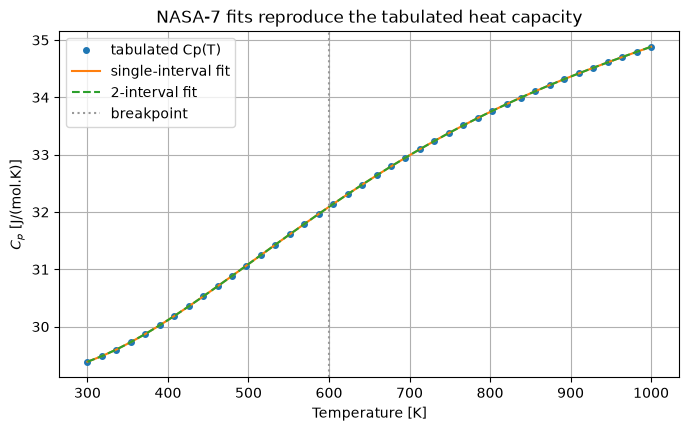

In [5]:
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True

fig, ax = plt.subplots()
ax.plot(T, cp_true, "o", ms=4, label="tabulated Cp(T)")
ax.plot(T, cp_fit, "-", label="single-interval fit")
ax.plot(T, cp_fit_multi, "--", label="2-interval fit")
ax.axvline(600.0, color="0.6", ls=":", label="breakpoint")
ax.set_xlabel("Temperature [K]")
ax.set_ylabel(r"$C_p$ [J/(mol.K)]")
ax.set_title("NASA-7 fits reproduce the tabulated heat capacity")
ax.legend()
plt.show()


## 6. A more complex example: wide range and noisy data

Two realistic complications remain. First, a single 7-term polynomial cannot
bend enough to follow $C_p(T)$ over a wide range — here CO₂ from 300 to
6000 K. We fit it once with `fit_nasa7` (one interval) and once with
`fit_nasa7_multi` using NASA-style breakpoints at 1000 K and 4000 K.
Second, real data is noisy: we add Gaussian noise ($\sigma = 1.5$ J/(mol·K)),
fit with inverse-variance weights, and anchor $s_\mathrm{ref}$ to recover
absolute entropy.


In [6]:
# Part 1: CLEAN wide-range data - a single 7-term polynomial cannot bend enough
rng = np.random.default_rng(42)
Twide = np.linspace(300, 6000, 200)
with ThermochemicalCalculator() as calc:
    co2 = calc.get_available_species("CO2", exact_match=True)[0].id
    cp_true = np.array([calc.calculate_properties(co2, t).cp for t in Twide])
    s_ref = calc.calculate_properties(co2, 298.15).s

# Single interval across the whole range vs NASA-style 3 intervals
c1 = fit_nasa7(Twide, cp_true)
c3 = fit_nasa7_multi(Twide, cp_true, [1000.0, 4000.0])

def eval3(coeffs, t):
    i = 0 if t <= 1000.0 else (1 if t <= 4000.0 else 2)
    return ThermoDBQuery.calculate_cp(coeffs[i], t) * R_GLENN

cp1 = np.array([ThermoDBQuery.calculate_cp(c1, t) * R_GLENN for t in Twide])
cp3 = np.array([eval3(c3, t) for t in Twide])

err1 = np.max(np.abs(cp1 - cp_true))
err3 = np.max(np.abs(cp3 - cp_true))
print(f"single-interval max error = {err1:.4f} J/(mol.K)")
print(f"3-interval    max error = {err3:.4f} J/(mol.K)")
print(f"improvement factor       = {err1/err3:.0f}x")


single-interval max error = 0.2249 J/(mol.K)
3-interval    max error = 0.0033 J/(mol.K)
improvement factor       = 69x


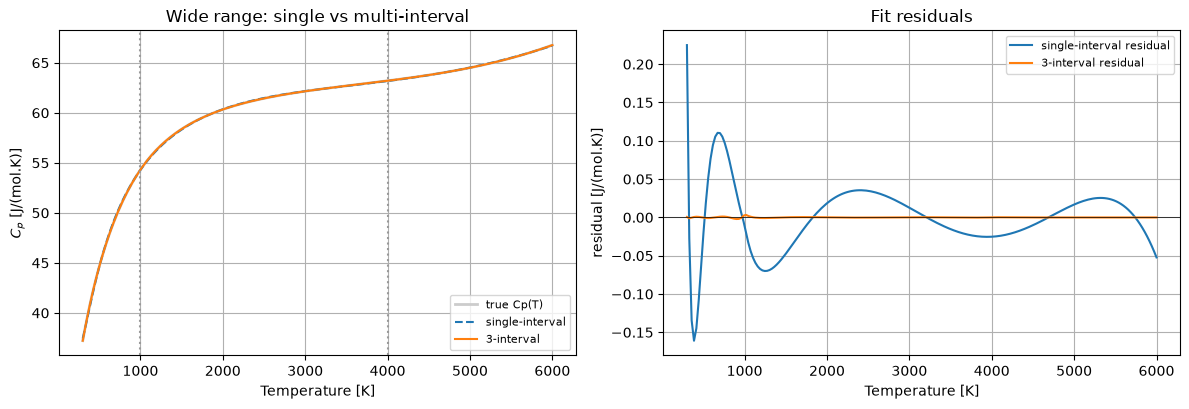

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

ax1.plot(Twide, cp_true, color="0.8", lw=2, label="true Cp(T)")
ax1.plot(Twide, cp1, "--", label="single-interval")
ax1.plot(Twide, cp3, "-", label="3-interval")
ax1.axvline(1000.0, color="0.6", ls=":")
ax1.axvline(4000.0, color="0.6", ls=":")
ax1.set_xlabel("Temperature [K]")
ax1.set_ylabel(r"$C_p$ [J/(mol.K)]")
ax1.set_title("Wide range: single vs multi-interval")
ax1.legend(fontsize=8)

ax2.plot(Twide, cp1 - cp_true, label="single-interval residual")
ax2.plot(Twide, cp3 - cp_true, label="3-interval residual")
ax2.axhline(0.0, color="k", lw=0.5)
ax2.set_xlabel("Temperature [K]")
ax2.set_ylabel("residual [J/(mol.K)]")
ax2.set_title("Fit residuals")
ax2.legend(fontsize=8)

fig.tight_layout()
plt.show()


input noise sigma       = 1.50 J/(mol.K)
fit RMSE vs true curve  = 0.214 J/(mol.K)
S(298.15) from the fit = 213.787 J/(mol.K)  (s_ref = 213.787)


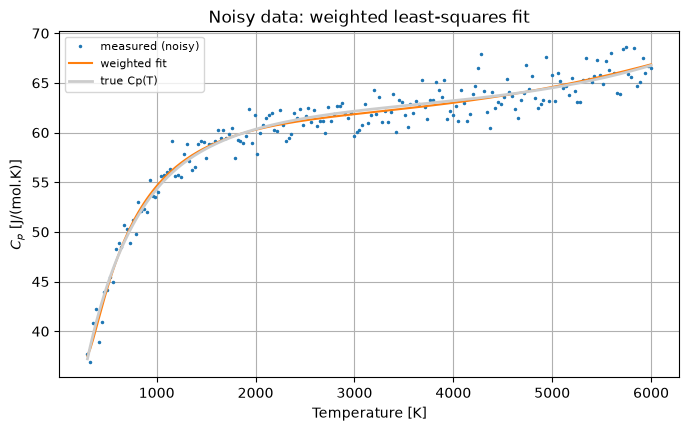

In [8]:
# Part 2: NOISY 'measured' data - weighted least squares + entropy anchor
sigma = 1.5  # J/(mol.K) noise level
cp_meas = cp_true + rng.normal(0.0, sigma, size=Twide.shape)
weights = np.full_like(Twide, 1.0 / sigma**2)  # inverse-variance weights

c_w = fit_nasa7(Twide, cp_meas, weights=weights, s_ref=s_ref)
cp_w = np.array([ThermoDBQuery.calculate_cp(c_w, t) * R_GLENN for t in Twide])
rmse = np.sqrt(np.mean((cp_w - cp_true) ** 2))

print(f"input noise sigma       = {sigma:.2f} J/(mol.K)")
print(f"fit RMSE vs true curve  = {rmse:.3f} J/(mol.K)")

# Entropy anchor check
s_check = ThermoDBQuery.calculate_s(c_w, 298.15) * R_GLENN
print(f"S(298.15) from the fit = {s_check:.3f} J/(mol.K)  (s_ref = {s_ref:.3f})")

fig, ax = plt.subplots()
ax.plot(Twide, cp_meas, ".", ms=3, label="measured (noisy)")
ax.plot(Twide, cp_w, "-", label="weighted fit")
ax.plot(Twide, cp_true, color="0.8", lw=2, label="true Cp(T)")
ax.set_xlabel("Temperature [K]")
ax.set_ylabel(r"$C_p$ [J/(mol.K)]")
ax.set_title("Noisy data: weighted least-squares fit")
ax.legend(fontsize=8)
plt.show()


## Summary

- `fit_nasa7` recovers $a_1 \ldots a_7$ by least squares and anchors $b_1$ to
  $H^\circ(t_\mathrm{ref})$ (and $b_2$ to $S^\circ(t_\mathrm{ref})$ when given).
- `fit_nasa7_multi` splits the range at breakpoints with $C_p$ and $C_p'$
  continuity — over a wide range it beats a single interval by ~70×
  (0.22 vs 0.003 J/(mol·K) for CO₂, 300–6000 K).
- Inverse-variance weights and the $s_\mathrm{ref}$ anchor keep the fit robust
  on noisy data (RMSE well below the noise level).
